# CP2 analysis notebook

Graphical results for each stage of the project. All figures are produced by `plots.py`, the
same code that generates the documentation figures, and are numbered as in
`docs/stage1_evaluation.md` (Figures 1–4 appear in both; Figures 5–7 appear only here). Each figure's title and description are in the caption
directly below it.

The notebook trains no models from scratch: model predictions are read from the cache written by
`python validity.py`. If the cache is empty, the scorecard cell computes the missing predictions
(5–10 minutes, once). Only development-set ratings are used; the test set remains sealed.

**Terms.** An advisor's output for a grid is its *rating* (0 to 1). A grid *passes* an advisor when
its rating is at least 0.75, and is *valid* when it passes all four. The *development set* (`dev`
in the code) is the 4,000 rated grids per advisor used for training and validation; the *test set*
(the lockbox) is held out. An *out-of-fold prediction* is a grid's predicted rating from a model
that was not trained on that grid (`docs/stage1_evaluation.md`, "Out-of-fold predictions").

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd

import features
import plots
import validity

grids, dev = validity.load_dev()  # all 500,000 grids; test-set ratings are returned as NaN (missing)
print(f"{len(grids):,} grids; development-set ratings per advisor:",
      dict(zip(validity.ADVISORS, (~np.isnan(dev)).sum(0))))

500,000 grids; development-set ratings per advisor: {'Wellness': np.int64(4000), 'Tax': np.int64(4000), 'Transportation': np.int64(4000), 'Business': np.int64(4000)}


---
## Stage 1 · Data split

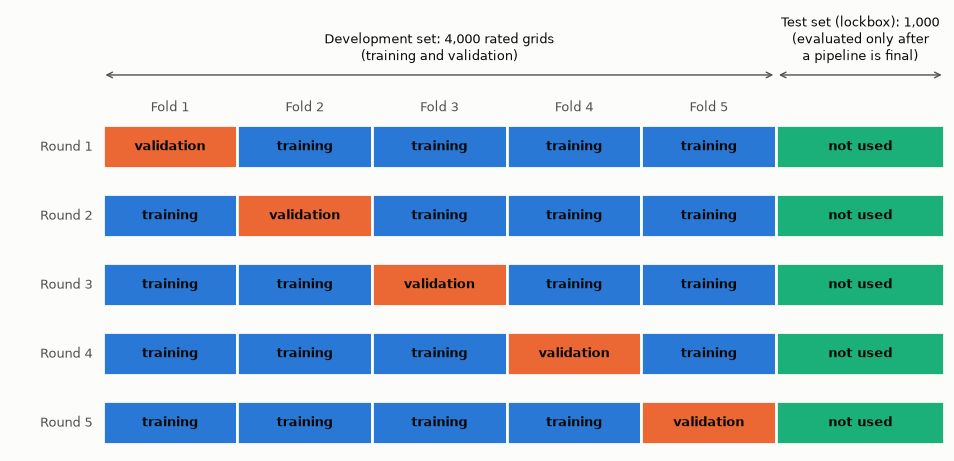

In [2]:
plots.fig_cv_rounds();

**Figure 1. Data split and five-fold cross-validation for one advisor.** The 5,000 rated
grids are divided into a development set of 4,000 grids and a test set (the lockbox) of 1,000. The
development set is divided into five folds of 800 grids. In each of five rounds, a new model is
trained on four folds and validated on the remaining one: fold 1 in round 1, fold 2 in round 2, and
so on. The test set is not used in any round. Each advisor's rated grids are split by the same
procedure.

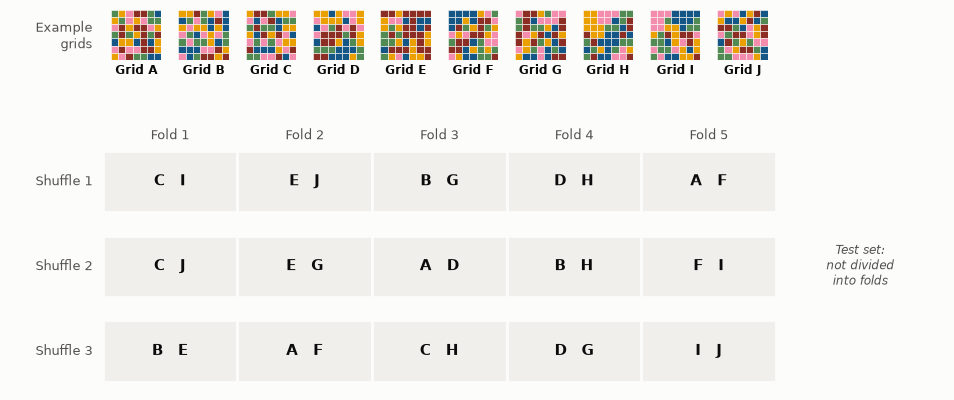

In [3]:
examples = grids[np.flatnonzero(~np.isnan(dev[:, 0]))[:10]]  # ten Wellness development-set grids
plots.fig_shuffles(examples);

**Figure 2. Shuffle procedure, illustrated with ten example grids (A–J) in place of the 4,000
development-set grids.** Each row shows one random assignment ("shuffle") of the same ten grids to
the five folds of Figure 1. Under shuffle 1, for example, round 1 trains on grids A, B, D–H and J
and validates on grids C and I (fold 1); under shuffle 2, round 1 validates on grids C and J
instead. Grid B falls in fold 3 under shuffle 1 and in fold 1 under shuffle 3. The five rounds are
run once for each of the three shuffles. The test set is never divided into folds.

---
## Stage 1 · Engineered features

Set `i` to any grid number from 0 to 499,999 to display that grid and its feature values.

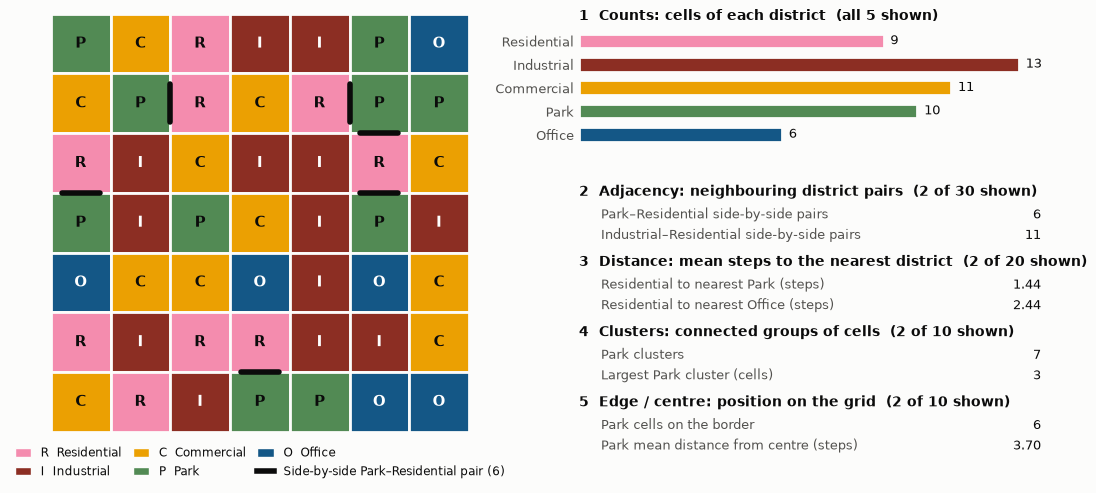

In [4]:
i = int(np.flatnonzero(~np.isnan(dev[:, 0]))[0])  # grid A of Figure 2 (dataset grid 12)
plots.fig_grid_features(grids[i]);

**Figure 3. One grid and 13 of its 75 engineered features.** Left: the selected grid (by
default, grid A of Figure 2, which is dataset grid 12), with each cell coloured and lettered by
district. The black bars mark its side-by-side Park–Residential pairs, the quantity counted by one
adjacency feature. Right: all five count features and two examples from each of the other four
groups. Each group repeats its pattern for every district or district pair; the table below lists
all 75 values.

In [5]:
values = features.engineered(grids[i : i + 1])[0]
group_of = {col: g for g, cols in features.FEATURE_GROUPS.items() for col in cols}
table = pd.DataFrame({
    "group": [group_of[c] for c in range(len(values))],
    "feature": features.ENGINEERED_NAMES,
    "value": np.round(values, 2),
})
pd.set_option("display.max_rows", 80)
table

,group,feature,value
0,counts,count Residential,9.00
1,counts,count Industrial,13.00
2,counts,count Commercial,11.00
3,counts,count Park,10.00
4,counts,count Office,6.00
5,adjacency,side-by-side Residential-Residential,2.00
6,adjacency,diagonal Residential-Residential,3.00
7,adjacency,side-by-side Residential-Industrial,11.00
8,adjacency,diagonal Residential-Industrial,10.00
9,adjacency,side-by-side Residential-Commercial,9.00


---
## Stage 1 · Model scorecard

Four models are compared: two model types, each given two kinds of input.
- **Ridge regression:** a linear model (its predicted rating is a weighted sum of the inputs).
- **Gradient-boosted trees (GBM, gradient boosting machine):** several hundred small decision
  trees added one at a time, each correcting the errors of those before it (LightGBM library).
- **One-hot inputs:** 245 indicators recording each cell's district. **Engineered features:** the
  75 relationship measures of Figure 3.

The primary model is GBM on engineered features. A model *approves* a grid for an advisor when the
grid's predicted rating is high enough; *precision* is the fraction of approved grids that truly
pass. The comparison metric is the **approval count at 98% precision** (Figure 4); `docs/stage1_evaluation.md`
(Model scorecard) explains the choice of 98%.

In [6]:
results = validity.scorecard(verbose=False)  # read from the cache
validity.print_scorecard(results)
validity.print_precision_tradeoff(validity.precision_tradeoff(results, "gbm_engineered"), "gbm_engineered")


Approval count at 98% precision, of 4,000 development-set grids per advisor:
mean over the 3 shuffles [the 3 per-shuffle counts]
  variant                         Wellness                   Tax        Transportation              Business
  ridge_onehot            67 [    68/66/67]     611 [ 612/608/612]       0 [       0/0/0]      40 [     4/62/55]
  gbm_onehot              76 [   31/78/118]     543 [ 562/512/556]       5 [       4/7/5]      82 [   104/74/69]
  ridge_engineered       242 [ 261/241/223]     817 [ 814/822/815]      19 [     1/30/27]     182 [ 185/185/177]
  gbm_engineered         534 [ 550/523/528]     828 [ 842/815/828]     744 [ 745/750/738]     836 [ 847/814/847]

Approval cut-off: the predicted rating of the last grid approved at 98% precision,
mean over the 3 shuffles. A grid is approved for an advisor at or above it.
  variant                         Wellness                   Tax        Transportation              Business
  ridge_onehot                       0.9

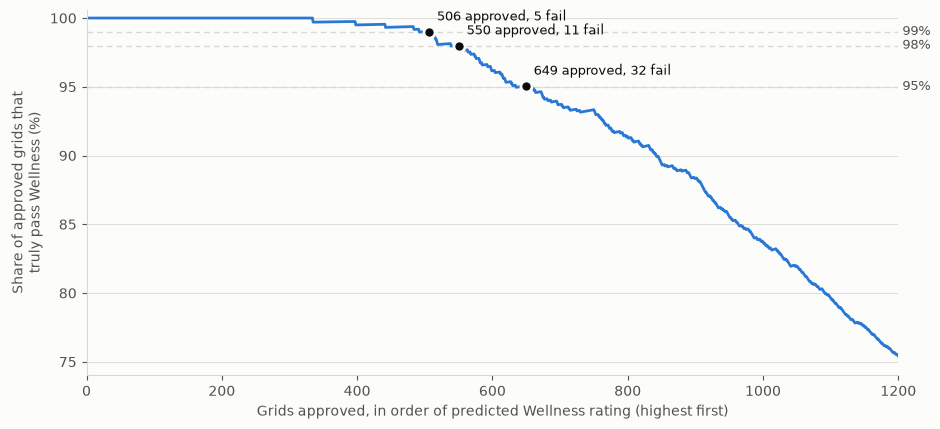

In [7]:
plots.fig_approval_curve(results);

**Figure 4. How the approval count at 98% precision is measured (Wellness, primary model,
shuffle 1).** The 4,000 development-set grids are sorted by predicted Wellness rating, highest first,
and approved one at a time from the left. The curve shows the share of the approved grids that truly
pass Wellness (true rating at least 0.75). The approval count at a precision level is the last point
at which the curve is at or above that level. The marked points show, for precision levels of 95%,
98% and 99%, how many grids are approved and how many of those truly fail. Relaxing the requirement
from 98% to 95% approves 99 more grids but adds 21 failures: about one in five of the added grids
fails. Each invalid grid in a submission scores nothing, so this is a direct loss of score unless
the wider choice yields a more diverse final set (`docs/stage1_evaluation.md`, "Risk of approving
more grids"). The scorecard reports the mean of the three shuffles' approval counts.

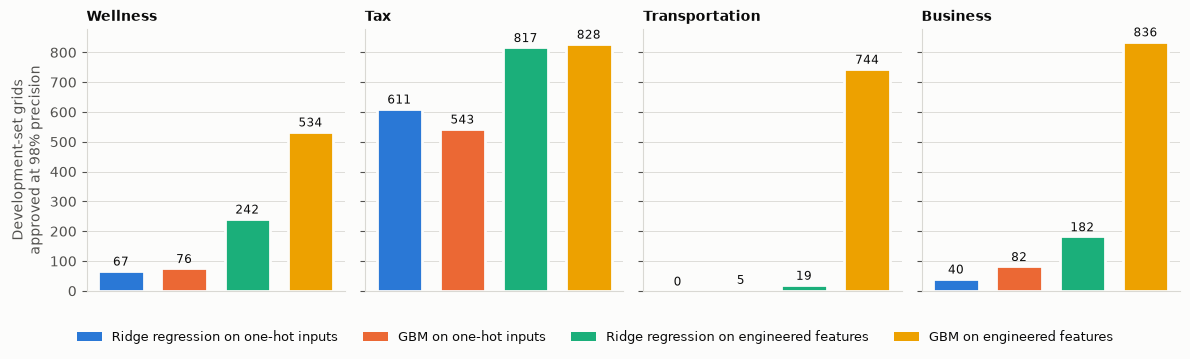

In [8]:
plots.fig_scorecard(results);

**Figure 5. Approval count at 98% precision, by model and advisor.** Each bar is the
number of the 4,000 development-set grids per advisor that a model can approve while at least 98%
of its approvals truly pass that advisor, averaged over the three shuffles. Higher is better. GBM on
engineered features has the highest count for every advisor. For Tax, its lead over Ridge regression
on engineered features (828 against 817) is within the variation between shuffles.

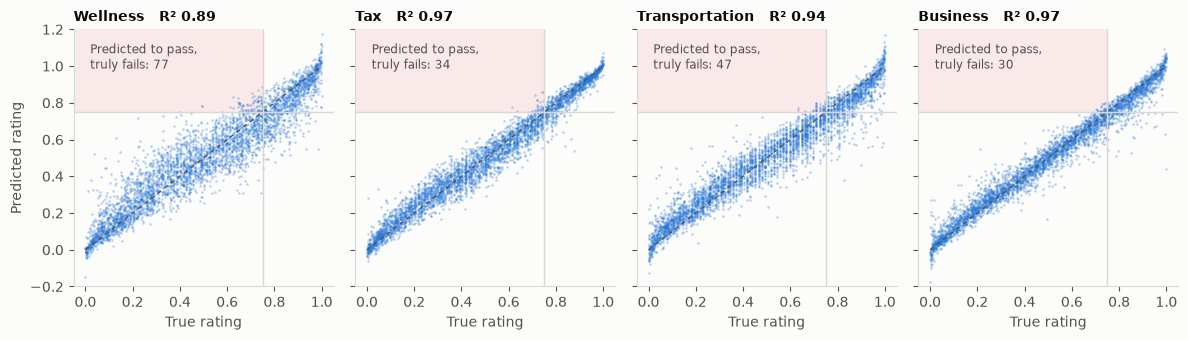

In [9]:
plots.fig_pred_vs_actual(results, "gbm_engineered");

**Figure 6. Predicted versus true rating for the primary model (GBM on engineered
features).** Each point is one development-set grid, predicted by a model that did not train on it
(shuffle 1). The dashed line marks perfect prediction, and the grey lines mark the 0.75 threshold.
The shaded region contains grids predicted to pass (predicted rating at least 0.75) that truly fail
(true rating below 0.75); their number is shown in each panel. These errors are why a grid is
approved only above a higher cut-off (0.765–0.824 for this model at 98% precision; see the scorecard
output above), and why designs get a further safety margin in Stage 3.

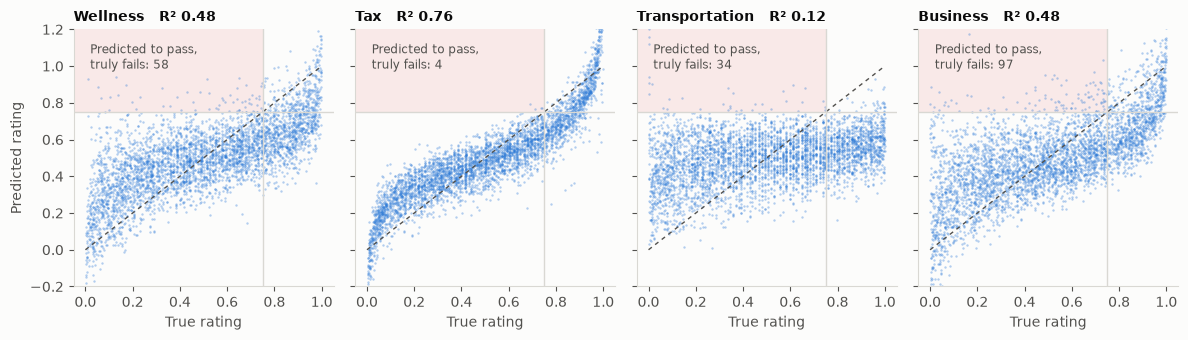

In [10]:
plots.fig_pred_vs_actual(results, "ridge_onehot");

**Figure 7. Predicted versus true rating for the linear baseline (Ridge regression on one-hot
inputs).** Layout as in Figure 6, except that the plotted range is fixed at −0.2 to 1.2, so this
model's predictions outside it are not drawn. For Transportation, the predictions vary little across
the range of true ratings, and the highest predictions all belong to grids that truly fail (two of
them lie above the plotted range), so no number of approvals reaches 98% precision.

---
**Further exploration.** Change `i` in the Engineered features section to inspect other grids. In
the last plotting cell, substitute `"gbm_onehot"` (GBM on one-hot inputs) to compare the same model
type with and without engineered features. `plots.fig_approval_curve(results, advisor="Tax")` draws
Figure 4 for another advisor.